# Introduction to Artificial Neural Networks (ANN)

## Purpose

Build a small multilayer perceptron (MLP) from scratch to see how forward propagation, backpropagation, and gradient descent work together. Fit points inside and outside a circle, inspect prediction errors, and explore how hidden neurons combine to form a nonlinear decision boundary.

## Contents

1. [Setup](#setup)
2. [A multilayer perceptron](#multilayer-perceptron)
3. [Sigmoid and binary cross-entropy](#sigmoid-and-bce)
4. [Implement the network](#implement-the-network)
5. [Circle data](#circle-data)
6. [Training and evaluation](#training-and-evaluation)
7. [Inspect the hidden neurons](#hidden-neurons)
8. [Ideas to deepen your knowledge](#further-experiments)
9. [Takeaways](#takeaways)

<a id="setup"></a>
## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

class_cmap = ListedColormap(["blue", "red"])


<a id="multilayer-perceptron"></a>
## A multilayer perceptron

We will define an artificial neural network for binary classification that implements the following methods:
- `__init__`
- `fit(X, y)`
- `predict(X)`

Each layer in our network will be an instance of the class `_Layer` with the following attributes:
- number of inputs
- number of units (neurons)

All units are sigmoid neurons:
- The nonlinear activation function in each neuron is the sigmoid function.

The loss function is binary cross-entropy (BCE).

### Representation of Weights and Biases

A single sigmoid neuron has the same form as binary logistic regression. Here we represent an entire layer using matrix operations. The network has one hidden layer and one output layer; the input features are not counted as a parameterized layer.

If a layer has $m$ inputs (features), each neuron has $m$ weights and one bias. If the layer has $k$ neurons, we can represent its parameters as:

For $n$ samples, the input matrix $X$ has shape $(n, m)$.

- **Weight matrix**: $W$ of shape $(m, k)$, where each column contains the weights of one neuron.
- **Bias vector**: $b$ of shape $(1, k)$, containing one bias per neuron.

The linear combinations for all neurons and samples are computed as:

$$
Z = XW + b
$$

where $Z$ has shape $(n, k)$. NumPy broadcasts the bias vector $b$ across all $n$ samples.

Applying the sigmoid activation function element-wise gives:

$$
A = \sigma(Z)
$$

where $A$ has shape $(n, k)$ and contains the activations of all $k$ neurons for all $n$ samples.

For the final layer of a binary classifier, $k=1$, so the output $\hat{y}$ has shape $(n, 1)$.

<a id="sigmoid-and-bce"></a>
## Sigmoid and binary cross-entropy

All neurons use the sigmoid activation. The loss is mean binary cross-entropy over the examples. Its derivative below is with respect to the output probabilities; `_Layer.backward` applies the sigmoid derivative. The factor `1/n` is therefore applied once, in the loss derivative. Clipping probabilities keeps the loss and its derivative finite near 0 and 1.

In [2]:
def sigma(z):
    """Sigmoid, evaluated stably for large positive or negative inputs."""
    return np.exp(-np.logaddexp(0, -np.asarray(z)))


def binary_cross_entropy(y, y_hat):
    """Mean BCE across n examples, as in the logistic regression notebook."""
    y = np.asarray(y).reshape(-1, 1)
    y_hat = np.clip(np.asarray(y_hat).reshape(-1, 1), 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))


def binary_cross_entropy_derivative(y, y_hat):
    """Derivative with respect to probabilities; includes the mean's 1/n."""
    y = np.asarray(y).reshape(-1, 1)
    y_hat = np.clip(np.asarray(y_hat).reshape(-1, 1), 1e-15, 1 - 1e-15)
    return (-y / y_hat + (1 - y) / (1 - y_hat)) / len(y)

<a id="implement-the-network"></a>
## Implement the network

First define a layer, then combine two layers into a binary classifier.

In [3]:
class _Layer:
    def __init__(self, inputs, outputs):
        """Initialize weights and biases of the layer."""
        self.w = np.random.randn(inputs, outputs) * 0.01  # shape: (inputs, outputs)
        self.b = np.zeros((1, outputs))                   # shape: (1, outputs)
        self.d_w = None
        self.d_b = None

    def forward(self, X):
        """Compute the forward pass."""
        self.X = X                                        # shape: (n, inputs)
        self.z = X @ self.w + self.b                       # shape: (n, outputs)
        self.y_hat = sigma(self.z)                         # shape: (n, outputs)
        return self.y_hat

    def backward(self, d_loss_d_y_hat):
        """Compute gradients and propagate them to the previous layer."""
        d_y_hat_d_z = self.y_hat * (1 - self.y_hat)   # sigmoid derivative; shape: (n, outputs)
        d_z = d_loss_d_y_hat * d_y_hat_d_z           # chain rule; shape: (n, outputs)

        self.d_w = self.X.T @ d_z                    # shape: (inputs, outputs)
        self.d_b = d_z.sum(axis=0, keepdims=True)    # shape: (1, outputs)

        return d_z @ self.w.T                        # shape: (n, inputs)

    def update(self, learning_rate):
        """Update weights and biases."""
        self.w -= learning_rate * self.d_w
        self.b -= learning_rate * self.d_b

    def print_status(self):
        print("w, b =", self.w, self.b)

The class `NeuralNetwork` uses two instances of `_Layer`. Backpropagation computes both layers' gradients before gradient descent updates either layer.

In [4]:
class NeuralNetwork:
    """A simple 2-layer neural network with sigmoid activation for binary classification."""

    def __init__(self, inputs, hidden, outputs=1):
        """Initialize a neural network with 2 layers."""
        if outputs != 1:
            raise ValueError("This implementation supports binary classification with one output.")
        self.layer1 = _Layer(inputs, hidden)          # Hidden layer: inputs -> hidden neurons
        self.layer2 = _Layer(hidden, outputs)         # Output layer: hidden -> outputs

    def forward(self, X):
        """Forward pass of the neural network."""
        return self.layer2.forward(self.layer1.forward(X))  # shape: (n, outputs)

    def backward(self, y_hat, y):
        """Backward pass of the neural network."""
        gradient = binary_cross_entropy_derivative(y, y_hat)  # shape: (n, 1), includes 1/n
        gradient = self.layer2.backward(gradient)             # shape: (n, hidden)
        self.layer1.backward(gradient)

    def update(self, learning_rate):
        """Update the weights of the neural network."""
        self.layer1.update(learning_rate)
        self.layer2.update(learning_rate)

    def print_status(self):
        self.layer1.print_status()
        self.layer2.print_status()

    # Probability output is a column (n, 1); labels are one-dimensional (n,).
    def predict_proba(self, X):
        return self.forward(X)                         # shape: (n, 1)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).ravel()  # shape: (n,)

    def fit(self, X, y, epochs=10000, learning_rate=1.0, verbose=False):
        """Fit the model using gradient descent."""
        y = np.asarray(y).reshape(-1, 1)               # Ensure shape: (n, 1)

        for epoch in range(epochs):
            y_hat = self.forward(X)                    # Forward propagation
            self.backward(y_hat, y)                    # Backpropagation

            if verbose and epoch % 1000 == 0:
                loss = binary_cross_entropy(y, y_hat)
                print("----------------------\nEpoch:", epoch, "Error:", loss)
                self.print_status()

            self.update(learning_rate)                 # Gradient descent

        return self

<a id="circle-data"></a>
## Circle data

Separate points inside a circle of radius $\sqrt{0.5}$ from points outside. Generate 100 training points and 10,000 independent test points in $[-1, 1]^2$.

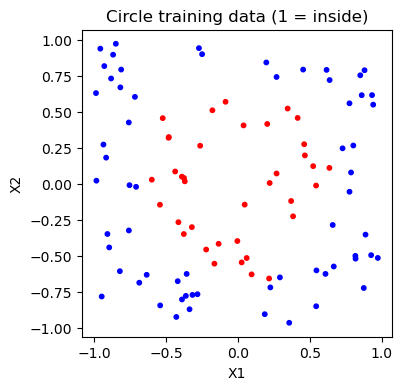

In [5]:
# Data
# Circle centered at (0, 0), with radius sqrt(0.5): x1^2 + x2^2 < 0.5
# We generate random points in the square [-1, 1] x [-1, 1] and check if they are inside the circle
np.random.seed(42)
m_train, m_test = 100, 10000
X_train = 2 * np.random.rand(m_train, 2) - 1
y_train = (X_train[:, 0]**2 + X_train[:, 1]**2 < 0.5).astype(int).reshape(-1, 1)    # r^2 = 0.5

X_test = 2 * np.random.rand(m_test, 2) - 1
y_test = (X_test[:, 0]**2 + X_test[:, 1]**2 < 0.5).astype(int).reshape(-1, 1)    # r^2 = 0.5

plt.figure(figsize=(4, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.ravel(), cmap=class_cmap, vmin=0, vmax=1, s=10)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Circle training data (1 = inside)")
plt.gca().set_aspect("equal")
plt.show()

<a id="training-and-evaluation"></a>
## Training and evaluation

**Predict.** With four hidden sigmoid neurons, will the learned boundary be a perfect circle? Run the network, then compare its predictions and errors with the circular labeling rule.

In [6]:
# train the neural network on these data
np.random.seed(42)
nn = NeuralNetwork(2, 4, 1)    # 2 inputs, 4 hidden neurons, 1 output
learning_rate = 1
nn.fit(X_train, y_train, 10000, learning_rate, verbose=True)  # 10,000 epochs

print(f"Training accuracy: {np.mean(nn.predict(X_train) == y_train.ravel()):.3f}")
print(f"Test accuracy: {np.mean(nn.predict(X_test) == y_test.ravel()):.3f}")

----------------------
Epoch: 0 Error: 0.6925935149028084
w, b = [[ 0.00496714 -0.00138264  0.00647689  0.0152303 ]
 [-0.00234153 -0.00234137  0.01579213  0.00767435]] [[0. 0. 0. 0.]]
w, b = [[-0.00469474]
 [ 0.0054256 ]
 [-0.00463418]
 [-0.0046573 ]] [[0.]]
----------------------
Epoch: 1000 Error: 0.658825066382561
w, b = [[-0.09230956 -0.09220571 -0.08422808 -0.07623876]
 [-0.15260716 -0.14258722 -0.12424548 -0.13366752]] [[-0.00844399 -0.00776892 -0.00492532 -0.00529202]]
w, b = [[-0.19095806]
 [-0.17821474]
 [-0.16772585]
 [-0.17068669]] [[-0.17901015]]
----------------------
Epoch: 2000 Error: 0.658731217185183
w, b = [[-0.15922417 -0.15268506 -0.13694641 -0.12967497]
 [-0.26224115 -0.24111681 -0.21077513 -0.22318904]] [[-0.079058   -0.06648054 -0.04841031 -0.05151069]]
w, b = [[-0.26448569]
 [-0.24243821]
 [-0.21604389]
 [-0.22206652]] [[-0.07200946]]
----------------------
Epoch: 3000 Error: 0.6586516574678614
w, b = [[-0.22197598 -0.19029866 -0.15159504 -0.14421431]
 [-0.36178

### Plot the decision boundary

Color the test points by predicted class to reveal the learned regions.

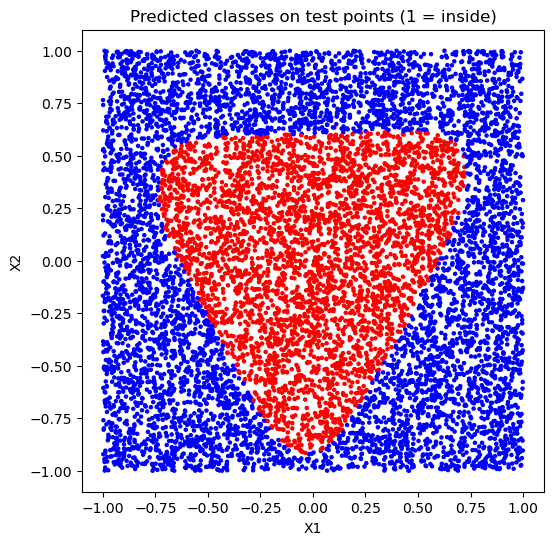

In [7]:
# Plot the decision boundary
y_hat = nn.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_hat.ravel(), cmap=class_cmap, vmin=0, vmax=1, s=5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Predicted classes on test points (1 = inside)")
plt.gca().set_aspect("equal")
plt.show()

### Inspect the errors

True positive: 3284
True negative: 5616
False positive: 480
False negative: 620


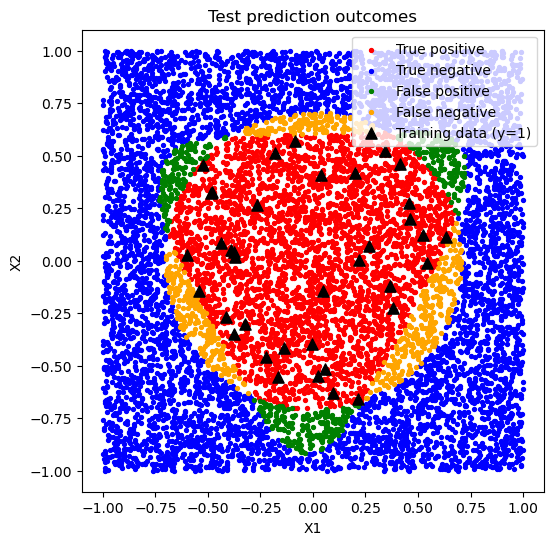

In [8]:
# Group test points by their actual and predicted labels.
y_hat = nn.predict(X_test)
categories = [
    (1, 1, "True positive", "red"),
    (0, 0, "True negative", "blue"),
    (0, 1, "False positive", "green"),
    (1, 0, "False negative", "orange"),
]

plt.figure(figsize=(6, 6))
for actual, predicted, label, color in categories:
    mask = (y_test.ravel() == actual) & (y_hat == predicted)
    print(f"{label}: {mask.sum()}")
    plt.scatter(X_test[mask, 0], X_test[mask, 1],
                color=color, s=8, label=label)

# Keep the positive training examples visible using a distinct marker.
plt.scatter(X_train[y_train.ravel() == 1, 0], X_train[y_train.ravel() == 1, 1],
            color="black", marker="^", s=65,
            label="Training data (y=1)")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Test prediction outcomes")
plt.gca().set_aspect("equal")
plt.legend()
plt.show()


**Think.** Could a single sigmoid neuron also fit this circular classification rule? Explain your reasoning, and optionally test it using the single-neuron implementation in the [logistic regression notebook](../../07_sgd/conceptual/logistic_regression.ipynb).

In [9]:
# Your code goes here

<a id="hidden-neurons"></a>
## Inspect the hidden neurons

**Predict.** What shape will each hidden neuron's threshold boundary have? Compare these plots with the network's overall decision boundary.

The plots show whether each activation is at least 0.5; the network itself uses the continuous sigmoid activations.

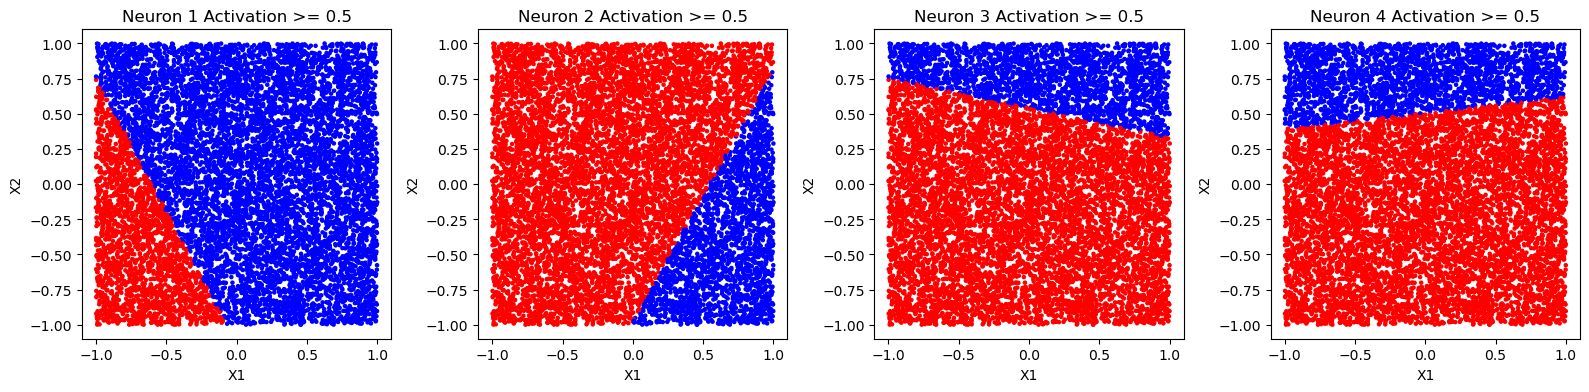

In [10]:
# Inspect the inner workings of the neural network by plotting the decision boundary and the hidden layer activations
# The hidden layer activations are the output of the first layer of the neural network
hidden_activations = nn.layer1.forward(X_test)
# binarize the hidden activations based on the threshold 0.5
hidden_activations = hidden_activations >= 0.5

# Plot a figure for each neuron
fig, axes = plt.subplots(1, hidden_activations.shape[1], figsize=(4 * hidden_activations.shape[1], 4))
axes = np.atleast_1d(axes).ravel()

for i in range(hidden_activations.shape[1]):
    axes[i].scatter(X_test[:, 0], X_test[:, 1], c=hidden_activations[:, i], cmap=class_cmap, vmin=0, vmax=1, s=5)
    axes[i].set_title(f'Neuron {i+1} Activation >= 0.5')
    axes[i].set_xlabel('X1')
    axes[i].set_ylabel('X2')
    axes[i].set_aspect('equal')

plt.tight_layout()
plt.show()

<a id="further-experiments"></a>
## Ideas to deepen your knowledge

1. Are the hidden neurons the same regardless of initialization? Change the initialization seed before creating the network while keeping the data fixed.
2. How does changing the number of neurons in the hidden layer change the final fit?
3. What happens if we add noise to the training data?
4. Can our neural network also fit more interesting shapes, such as a heart? The cell below prepares labels and plots the target shape; fitting it is left to you.
5. Try applying our neural network to a real dataset, such as a binary subset of MNIST containing two digits. The current network has one output and supports binary classification; full ten-class MNIST would require changing the output and loss.

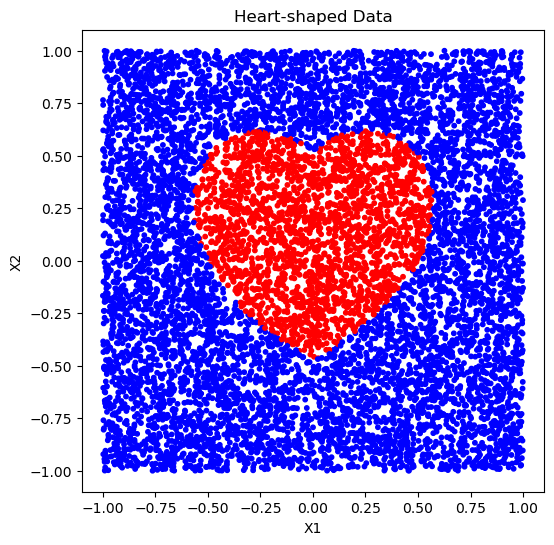

In [11]:
# Define the heart shape function
def is_heart(x1, x2):
    x = 2 * x1 
    y = 2 * x2 
    return ((x**2 + y**2 - 1)**3 - x**2 * y**3) <= 0

# Generate separate labels for the existing training and test points
y_train_heart = is_heart(X_train[:, 0], X_train[:, 1]).astype(int).reshape(-1, 1)
y_test_heart = is_heart(X_test[:, 0], X_test[:, 1]).astype(int).reshape(-1, 1)

# Plot the heart-shaped data
plt.figure(figsize=(6, 6))
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test_heart.ravel(), cmap=class_cmap, vmin=0, vmax=1, s=10)
plt.title('Heart-shaped Data')
plt.xlabel("X1")
plt.ylabel("X2")
plt.gca().set_aspect("equal")
plt.show()

<a id="takeaways"></a>
## Takeaways

- Matrix operations compute all neurons in a layer for all examples at once.
- Backpropagation applies the chain rule; gradient descent uses the resulting gradients to update weights and biases.
- Hidden sigmoid neurons combine to form a nonlinear decision boundary, although each neuron's 0.5 threshold is linear in its inputs.
- Test errors reveal where the learned boundary differs from the circular labeling rule.